# 1. Setup

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

CSV_PATH = '/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/base results and setup/test_set_merged.csv'
CLASSES = ["call", "dislike", "fist", "four", "like"]
PROB_COLS = [f"prob_{c}" for c in CLASSES]

df = pd.read_csv(CSV_PATH)
print(df.shape)
print("overall accuracy:", df["correct"].mean())

(1000, 15)
overall accuracy: 0.871


# 2. Per-class accuracy with confidence overlay

            accuracy    n  mean_conf_correct  mean_conf_incorrect
true_label                                                       
call           0.855  200           0.922689             0.739533
dislike        0.935  200           0.961507             0.729081
fist           0.850  200           0.940595             0.703338
four           0.930  200           0.967563             0.646187
like           0.785  200           0.864101             0.751006


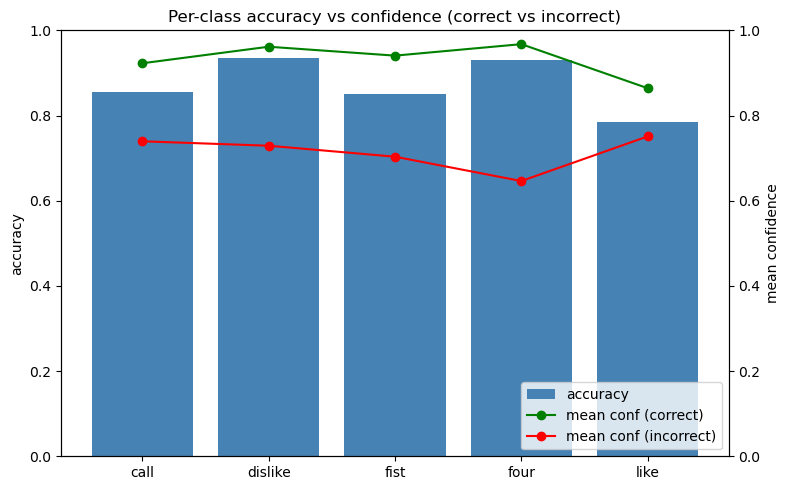

In [4]:
summary = df.groupby("true_label").agg(
    accuracy=("correct", "mean"),
    n=("correct", "size"),
    mean_conf_correct=("confidence", lambda s: s[df.loc[s.index, "correct"]].mean()),
    mean_conf_incorrect=("confidence", lambda s: s[~df.loc[s.index, "correct"]].mean()),
).reindex(CLASSES)
print(summary)

fig, ax1 = plt.subplots(figsize=(8, 5))
x = np.arange(len(CLASSES))
ax1.bar(x, summary["accuracy"], color="steelblue", label="accuracy")
ax1.set_ylabel("accuracy")
ax1.set_xticks(x)
ax1.set_xticklabels(CLASSES)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()
ax2.plot(x, summary["mean_conf_correct"], "o-", color="green", label="mean conf (correct)")
ax2.plot(x, summary["mean_conf_incorrect"], "o-", color="red", label="mean conf (incorrect)")
ax2.set_ylabel("mean confidence")
ax2.set_ylim(0, 1)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower right")
plt.title("Per-class accuracy vs confidence (correct vs incorrect)")
plt.tight_layout()
plt.show()

# 3. Confidence margin (top1 - top2) vs correctness

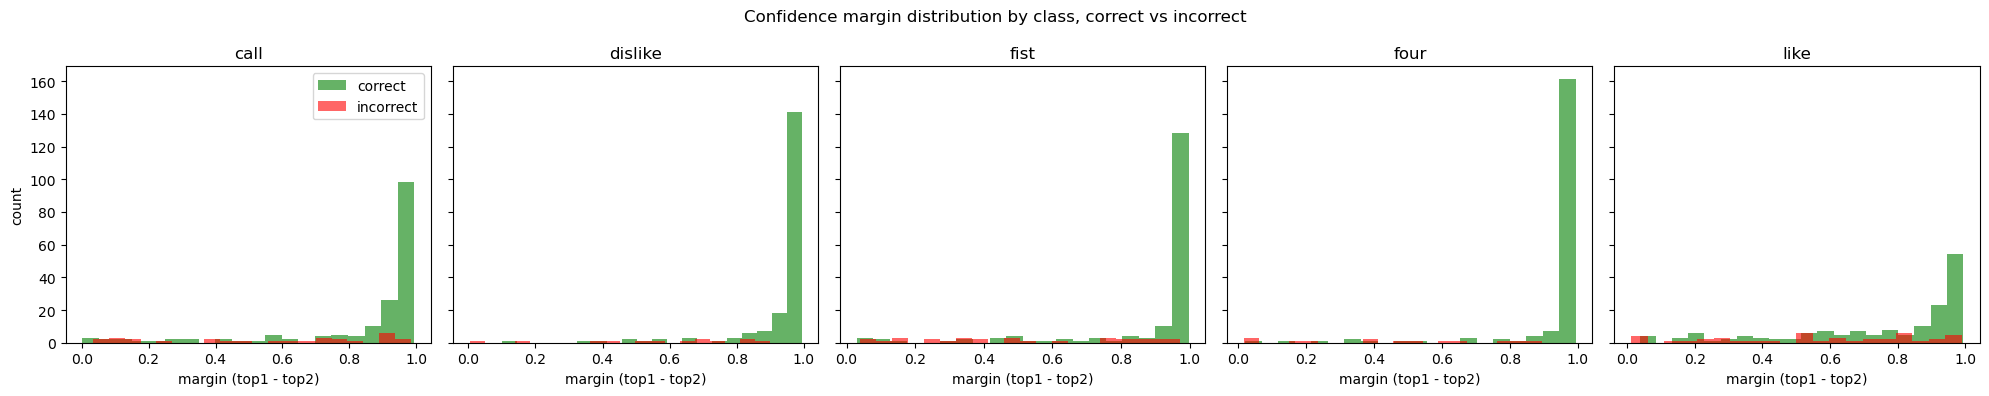

In [5]:
probs = df[PROB_COLS].values
sorted_probs = np.sort(probs, axis=1)
df["margin"] = sorted_probs[:, -1] - sorted_probs[:, -2]

fig, axes = plt.subplots(1, len(CLASSES), figsize=(20, 4), sharey=True)
for ax, cls in zip(axes, CLASSES):
    sub = df[df["true_label"] == cls]
    ax.hist(sub.loc[sub["correct"], "margin"], bins=20, alpha=0.6, label="correct", color="green")
    ax.hist(sub.loc[~sub["correct"], "margin"], bins=20, alpha=0.6, label="incorrect", color="red")
    ax.set_title(cls)
    ax.set_xlabel("margin (top1 - top2)")
axes[0].set_ylabel("count")
axes[0].legend()
plt.suptitle("Confidence margin distribution by class, correct vs incorrect")
plt.tight_layout()
plt.show()

# 4. Raw confusion matrix (counts)

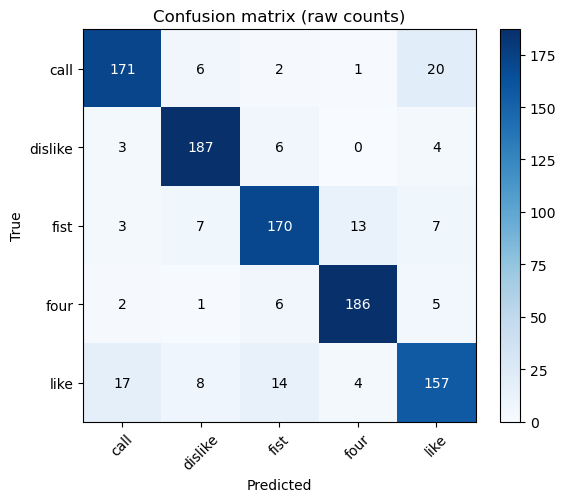

In [6]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(df["true_label"], df["pred_label"], labels=CLASSES)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES)))
ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=45)
ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix (raw counts)")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im)
plt.tight_layout()
plt.show()

# 5. Age vs accuracy, binned with confidence intervals

                  accuracy  correct_n    n    ci_low   ci_high
age_bin                                                       
(12.819, 23.116]     0.865        173  200  0.810709  0.905534
(23.116, 29.806]     0.855        171  200  0.799513  0.897106
(29.806, 37.198]     0.900        180  200  0.850594  0.934330
(37.198, 43.946]     0.910        182  200  0.862234  0.942313
(43.946, 79.97]      0.825        165  200  0.766356  0.871395


/var/folders/hx/pkkyjw395tng44gg777djtcc0000gp/T/ipykernel_32767/495776615.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_summary = df.groupby("age_bin").agg(


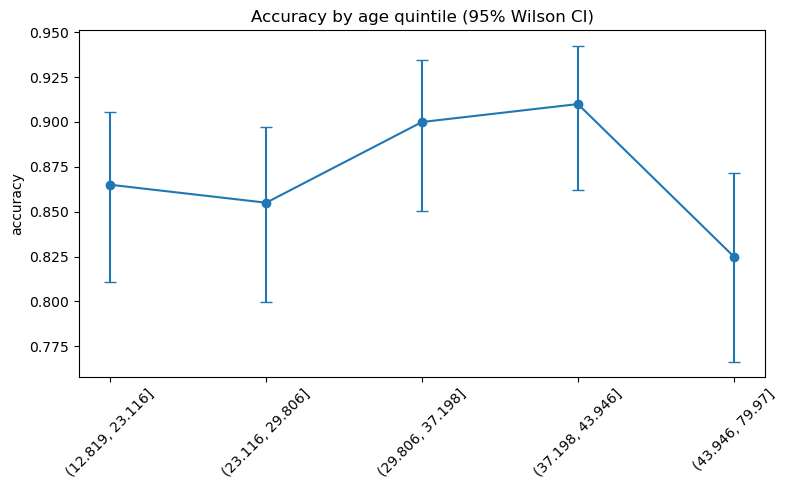

In [7]:
df["age_bin"] = pd.qcut(df["age"], q=5)

age_summary = df.groupby("age_bin").agg(
    accuracy=("correct", "mean"),
    correct_n=("correct", "sum"),
    n=("correct", "size"),
)
ci_low, ci_high = proportion_confint(age_summary["correct_n"], age_summary["n"], method="wilson")
age_summary["ci_low"] = ci_low
age_summary["ci_high"] = ci_high
print(age_summary)

x = np.arange(len(age_summary))
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(x, age_summary["accuracy"],
            yerr=[age_summary["accuracy"] - age_summary["ci_low"],
                  age_summary["ci_high"] - age_summary["accuracy"]],
            fmt="o-", capsize=4)
ax.set_xticks(x)
ax.set_xticklabels([str(i) for i in age_summary.index], rotation=45)
ax.set_ylabel("accuracy")
ax.set_title("Accuracy by age quintile (95% Wilson CI)")
plt.tight_layout()
plt.show()

# 6. Accuracy by hand, per class (interaction, not just marginal)

  leading_hand true_label      mean  size
0         left       call  0.875000    88
1         left    dislike  0.943820    89
2         left       fist  0.850000   100
3         left       four  0.916667    84
4         left       like  0.750000    80
5        right       call  0.839286   112
6        right    dislike  0.927928   111
7        right       fist  0.850000   100
8        right       four  0.939655   116
9        right       like  0.808333   120


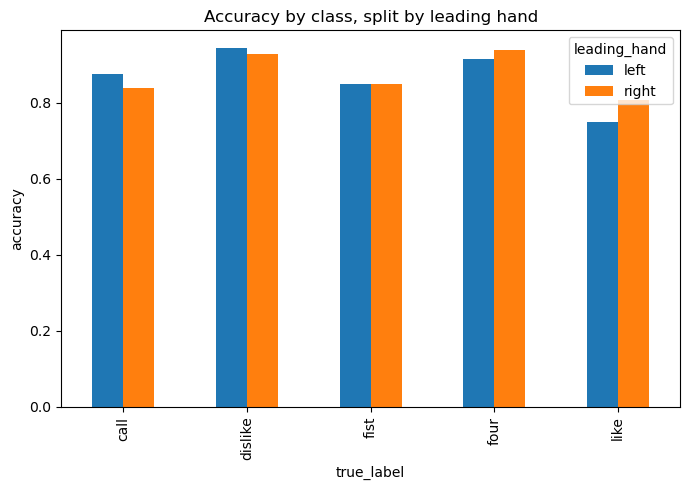

In [8]:
hand_class = df.groupby(["leading_hand", "true_label"])["correct"].agg(["mean", "size"]).reset_index()
print(hand_class)

pivot = hand_class.pivot(index="true_label", columns="leading_hand", values="mean").reindex(CLASSES)

fig, ax = plt.subplots(figsize=(7, 5))
pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("accuracy")
ax.set_title("Accuracy by class, split by leading hand")
plt.tight_layout()
plt.show()

# 7. Hand-detection confidence (leading_conf) vs classifier correctness

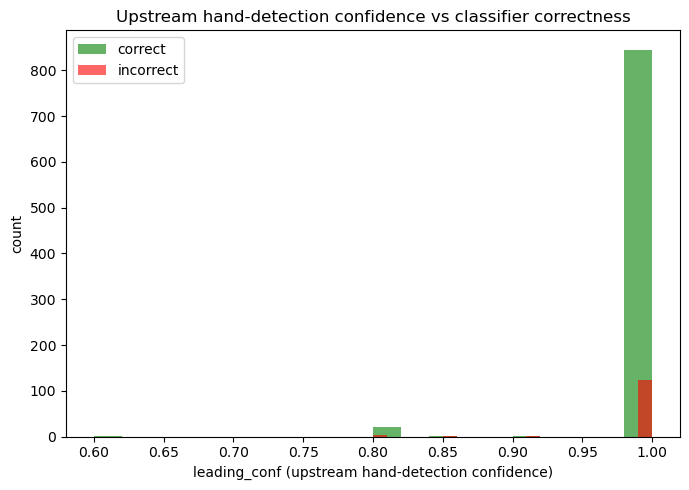

         count      mean       std  min  25%  50%  75%  max
correct                                                    
False    129.0  0.992045  0.037415  0.8  1.0  1.0  1.0  1.0
True     871.0  0.994134  0.034646  0.6  1.0  1.0  1.0  1.0


In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(df.loc[df["correct"], "leading_conf"], bins=20, alpha=0.6, label="correct", color="green")
ax.hist(df.loc[~df["correct"], "leading_conf"], bins=20, alpha=0.6, label="incorrect", color="red")
ax.set_xlabel("leading_conf (upstream hand-detection confidence)")
ax.set_ylabel("count")
ax.legend()
ax.set_title("Upstream hand-detection confidence vs classifier correctness")
plt.tight_layout()
plt.show()

print(df.groupby("correct")["leading_conf"].describe())

# 8. Accuracy by race and gender, with confidence intervals (small-n groups flagged)

            mean  sum  size    ci_low   ci_high
race                                           
Asian   0.923077   36    39  0.796789  0.973493
Black   0.900000    9    10  0.595850  0.982124
Indian  0.882353   15    17  0.656636  0.967120
White   0.880460  766   870  0.857212  0.900362
            mean  sum  size    ci_low   ci_high
gender                                         
female  0.864407  459   531  0.832657  0.890922
male    0.885057  385   435  0.851656  0.911718


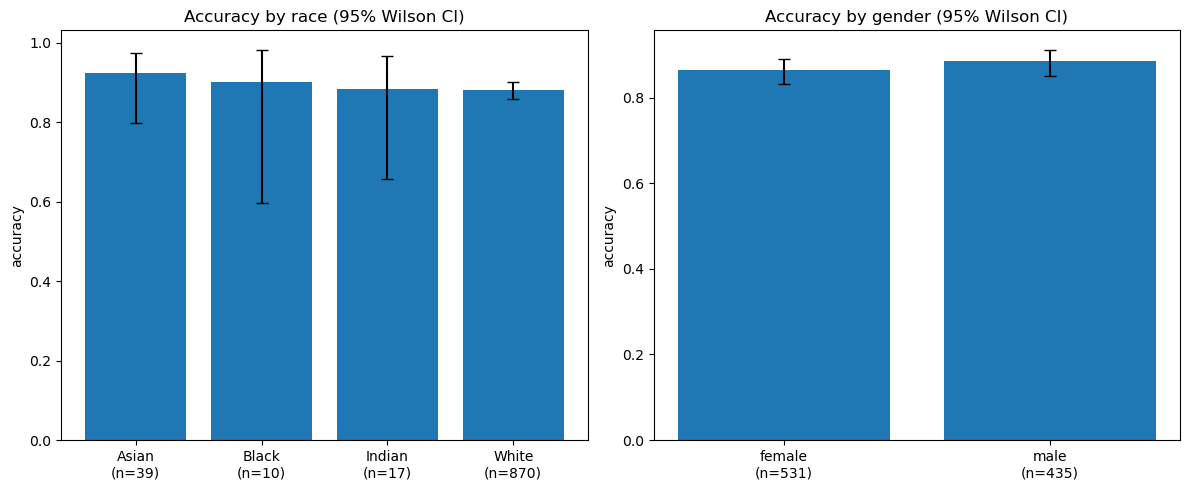

In [10]:
def summarize_group(col):
    g = df.groupby(col)["correct"].agg(["mean", "sum", "size"])
    ci_low, ci_high = proportion_confint(g["sum"], g["size"], method="wilson")
    g["ci_low"] = ci_low
    g["ci_high"] = ci_high
    return g

race_summary = summarize_group("race")
gender_summary = summarize_group("gender")
print(race_summary)
print(gender_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, summary, title in zip(axes, [race_summary, gender_summary], ["race", "gender"]):
    x = np.arange(len(summary))
    ax.bar(x, summary["mean"], yerr=[summary["mean"] - summary["ci_low"],
                                      summary["ci_high"] - summary["mean"]], capsize=4)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{idx}\n(n={n})" for idx, n in zip(summary.index, summary["size"])])
    ax.set_ylabel("accuracy")
    ax.set_title(f"Accuracy by {title} (95% Wilson CI)")
plt.tight_layout()
plt.show()

Brightness analysis:

In [11]:
import os
import glob
import numpy as np
from PIL import Image

DATA_ROOT = "/Users/Jakub/Desktop/School/VISAI/hagrid-sample-30k-384p/hagrid_30k"
CLASSES = ["call", "dislike", "fist", "four", "like"]

def find_path(img_id, label):
    pattern = os.path.join(DATA_ROOT, f"train_val_{label}", f"{img_id}.*")
    matches = glob.glob(pattern)
    return matches[0] if matches else None

def brightness_features(path):
    img = np.array(Image.open(path).convert("L"))  # grayscale
    h, w = img.shape
    border = img[np.r_[0:int(h*0.1), int(h*0.9):h], :].mean()  # top+bottom strips as background proxy
    overall = img.mean()
    return overall, border

df["path"] = df.apply(lambda r: find_path(r["id"], r["true_label"]), axis=1)
df[["brightness_overall", "brightness_background"]] = df["path"].apply(
    lambda p: pd.Series(brightness_features(p))
)

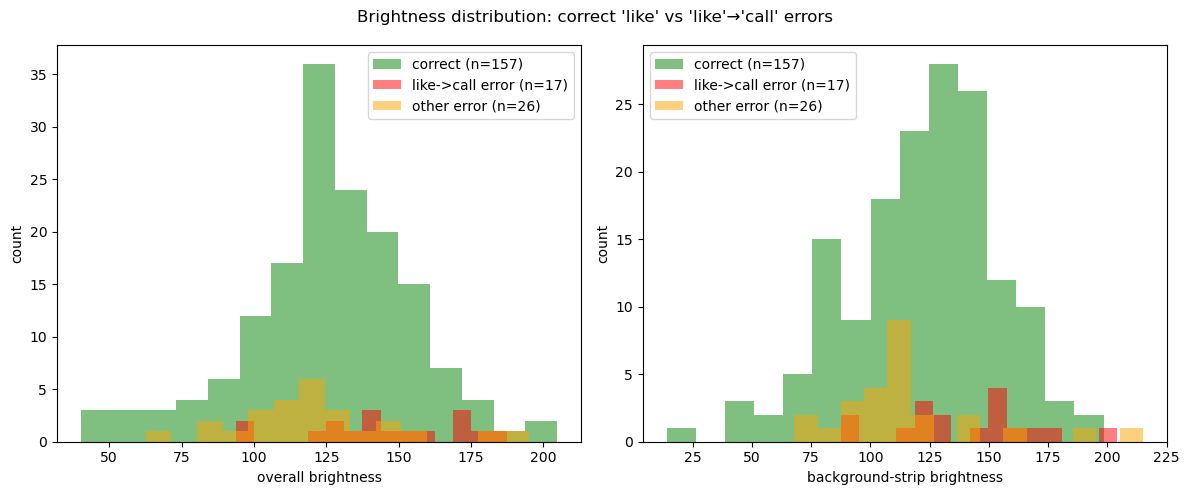

In [12]:
import matplotlib.pyplot as plt

like_df = df[df["true_label"] == "like"].copy()
like_df["group"] = np.where(
    like_df["correct"], "correct",
    np.where(like_df["pred_label"] == "call", "like->call error", "other error")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, title in zip(axes, ["brightness_overall", "brightness_background"],
                           ["overall brightness", "background-strip brightness"]):
    for group, color in zip(["correct", "like->call error", "other error"], ["green", "red", "orange"]):
        sub = like_df[like_df["group"] == group]
        if len(sub) > 0:
            ax.hist(sub[col], bins=15, alpha=0.5, label=f"{group} (n={len(sub)})", color=color)
    ax.set_xlabel(title)
    ax.set_ylabel("count")
    ax.legend()
plt.suptitle("Brightness distribution: correct 'like' vs 'like'→'call' errors")
plt.tight_layout()
plt.show()

In [14]:
print(like_df.groupby("group")[["brightness_overall", "brightness_background"]].agg(["mean", "median", "std", "count"]))

from scipy.stats import mannwhitneyu
correct_bg = like_df.loc[like_df["group"] == "correct", "brightness_background"]
error_bg = like_df.loc[like_df["group"] == "like->call error", "brightness_background"]
stat, p = mannwhitneyu(correct_bg, error_bg, alternative="two-sided")
print("background brightness, correct vs like->call error: p =", p)

correct_ov = like_df.loc[like_df["group"] == "correct", "brightness_overall"]
error_ov = like_df.loc[like_df["group"] == "like->call error", "brightness_overall"]
stat2, p2 = mannwhitneyu(correct_ov, error_ov, alternative="two-sided")
print("overall brightness, correct vs like->call error: p =", p2)

like_df.groupby("group")["brightness_overall"].median()

                 brightness_overall                               \
                               mean      median        std count   
group                                                              
correct                  126.297072  127.040039  28.668397   157   
like->call error         144.775465  142.734823  26.548771    17   
other error              121.078433  118.701377  28.023807    26   

                 brightness_background                               
                                  mean      median        std count  
group                                                                
correct                     121.850862  125.804737  31.691473   157  
like->call error            140.631040  149.135417  30.447533    17  
other error                 116.374224  114.136340  32.874115    26  
background brightness, correct vs like->call error: p = 0.027108154652971252
overall brightness, correct vs like->call error: p = 0.011265478808837862


group
correct             127.040039
like->call error    142.734823
other error         118.701377
Name: brightness_overall, dtype: float64